In [1]:
import os, pickle
from tqdm import tqdm  # Import tqdm for progress tracking
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
metadynamics_path = '../Metadynamics/analysis'

## Load Important Function

In [2]:
class Data:
    def __init__(self, array_list):
        self.array_list = array_list

    def save(self, filename):
        with open(filename, 'wb') as f:
            pickle.dump(self.array_list, f)

    @classmethod
    def load(cls, filename):
        with open(filename, 'rb') as f:
            array_list = pickle.load(f)
        return cls(array_list)
    

## Plain MD

In [3]:
def plain_md_index_to_state(index):
    """Converts an index (0-7) into a (3,) binary state array."""
    if not (0 <= index < 8):  # Ensure valid range (0-7)
        raise ValueError(f"Index out of range: {index}. Expected 0-7.")

    # Convert index to a 3-bit binary string
    binary_str = format(index, '03b')  # Example: 3 -> '011'
    
    # Convert binary string to NumPy array of integers
    state = np.array([int(bit) for bit in binary_str], dtype=int)

    return state

In [4]:
plain_md_path = '../Plain_MD/analysis'

omega_loaded = Data.load(f"{plain_md_path}/autocoorel_data/stationary_distributions_1us_5000stride.pkl").array_list
plain_md_pi_all_means = omega_loaded[0]
plain_md_pi_all_stds = omega_loaded[3]
plain_md_lagtimes_ns = omega_loaded[8]

plain_md_pi_all_means


array([[0.07208606, 0.08237758, 0.06160274, 0.06196209, 0.16750712,
        0.23583049, 0.15138174, 0.16725218],
       [0.07299126, 0.0832707 , 0.05968037, 0.06137586, 0.16825023,
        0.23849151, 0.1490885 , 0.16685157],
       [0.07324224, 0.08242628, 0.06049455, 0.06124403, 0.16903443,
        0.2379255 , 0.14995467, 0.16567829],
       [0.07302395, 0.08232158, 0.06091533, 0.06108564, 0.17029948,
        0.2362939 , 0.15049278, 0.16556735],
       [0.07336031, 0.08460444, 0.05949109, 0.0604987 , 0.16647672,
        0.24207446, 0.14857494, 0.16491934],
       [0.06985843, 0.08687631, 0.06010431, 0.05981032, 0.16153782,
        0.24578829, 0.14993805, 0.16608645],
       [0.07082557, 0.08427307, 0.06068494, 0.05963257, 0.17033718,
        0.23850706, 0.15253648, 0.16320311],
       [0.06941587, 0.08426143, 0.06042098, 0.05891904, 0.16753774,
        0.24178634, 0.15205667, 0.16560193],
       [0.06940269, 0.08507055, 0.06194772, 0.05943142, 0.16378675,
        0.24164314, 0.154524

## HREX

In [5]:
import numpy as np

def hrex_index_to_state(index):
    """
    Converts an index (0..47) into a (4,) array where the first three
    entries are bits (0 or 1) and the last entry is in [0..5].
    
    The logic is inverse of:
        index = 24*a + 12*b + 6*c + x,
    where a, b, c ∈ {0,1} and x ∈ [0..5].
    """
    if not (0 <= index < 48):
        raise ValueError(f"Index out of range: {index}. Expected 0..47.")
    
    # Extract the last element in [0..5]
    x = index % 6

    # The 3-bit portion is the integer in [0..7]
    binary_index = index // 6  # in [0..7]

    # Convert that integer into a 3-bit binary string, e.g. '011'
    binary_str = format(binary_index, '03b')

    # Parse into bits [a, b, c]
    bits = np.array([int(bit) for bit in binary_str], dtype=int)

    # Combine bits and x => [a, b, c, x]
    state = np.concatenate([bits, [x]])

    return state


In [6]:
hrex_path = '../HREX/analysis'

omega_loaded = Data.load(f"{hrex_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_stds = omega_loaded[3]
hrex_lagtimes_ns = omega_loaded[8]
pi_all_means


array([[0.01080345, 0.01038247, 0.00961046, ..., 0.03284667, 0.03409406,
        0.03474208],
       [0.01080354, 0.01038255, 0.00961053, ..., 0.03284606, 0.03409383,
        0.03474186],
       [0.01080362, 0.01038262, 0.0096106 , ..., 0.03284559, 0.03409426,
        0.03474224],
       ...,
       [0.00852623, 0.00894307, 0.00891276, ..., 0.03711898, 0.03652851,
        0.03560928],
       [0.00658093, 0.00717567, 0.00796964, ..., 0.03813086, 0.03739807,
        0.03502608],
       [0.00787518, 0.00881485, 0.0088421 , ..., 0.03259614, 0.03323627,
        0.03221976]], shape=(125, 48))

In [7]:
state0_index = [0, 6, 12, 18, 24, 30, 36, 42]

# Extract columns from the second dimension
pi_all_means_0 = pi_all_means[:, state0_index]
pi_all_stds_0 = pi_all_stds[:, state0_index]

# Compute row sums
row_sums = pi_all_means[:, state0_index].sum(axis=1, keepdims=True)
# Renormalize the mean
pi_all_means_0 /= row_sums
# Renormalize the standard deviation
pi_all_stds_0 /= row_sums

hrex_pi_all_means_0 = pi_all_means_0
hrex_pi_all_stds_0 = pi_all_stds_0


# Print shapes to confirm correctness
print(f"pi_all_means_0 shape: {hrex_pi_all_means_0.shape}")  # Expected: (4, 8)
print(f"pi_all_stds_0 shape: {hrex_pi_all_stds_0.shape}")  # Expected: (4, 8)

hrex_pi_all_means_0[0]


pi_all_means_0 shape: (125, 8)
pi_all_stds_0 shape: (125, 8)


array([0.06482059, 0.09186797, 0.06130279, 0.07076823, 0.15936155,
       0.23091623, 0.13949349, 0.18146915])

## EE

In [8]:
def ee_index_to_state(index):
    """
    Converts an index (0-31) into a (4,) array where the first three
    entries are binary bits (0 or 1) and the last entry is in [0..3].

    The logic is:
      - The last entry is index % 4.
      - The first 3 bits come from index // 4, in [0..7].
    """
    if not (0 <= index < 32):
        raise ValueError(f"Index out of range: {index}. Expected 0-31.")

    # Last element: in [0..3]
    last_part = index % 4

    # The 3-bit portion is the integer in [0..7]
    binary_index = index // 4  # in [0..7]

    # Convert that binary_index into a 3-bit binary string, e.g. '011'
    binary_str = format(binary_index, '03b')

    # Create an array of the three bits
    bits = np.array([int(bit) for bit in binary_str], dtype=int)

    # Combine [first 3 bits, last_part]
    state = np.concatenate([bits, [last_part]])
    
    return state

In [9]:
ee_path = '../EE/analysis'

omega_loaded = Data.load(f"{ee_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_stds = omega_loaded[3]
ee_lagtimes_ns = omega_loaded[8]
pi_all_means


array([[0.01482646, 0.01452865, 0.0147253 , 0.01573952, 0.02317327,
        0.02288201, 0.02331799, 0.02484235, 0.01486326, 0.01469336,
        0.01494557, 0.01599747, 0.0195415 , 0.01924097, 0.01950164,
        0.02079308, 0.03566468, 0.03507404, 0.03555934, 0.03777483,
        0.05752991, 0.05676037, 0.05751462, 0.06142221, 0.03433609,
        0.03381677, 0.03420408, 0.03642256, 0.04679269, 0.0463251 ,
        0.04703545, 0.05015487],
       [0.01482552, 0.01453279, 0.01472253, 0.01573293, 0.02317024,
        0.02288039, 0.02332062, 0.02483859, 0.0148641 , 0.01469491,
        0.01494695, 0.01598917, 0.01955157, 0.01925187, 0.01950847,
        0.0207866 , 0.03565462, 0.035073  , 0.0355467 , 0.03773232,
        0.05754336, 0.05678553, 0.05752464, 0.06139282, 0.03435347,
        0.03383574, 0.03420937, 0.03640498, 0.04680183, 0.04634501,
        0.04704074, 0.05013865],
       [0.01482755, 0.01453291, 0.01472849, 0.01574057, 0.02318031,
        0.02288957, 0.02332683, 0.02484876, 0.0148

In [10]:
state_index = [0, 4, 8, 12, 16, 20, 24, 28]
state_index = np.array(state_index)

state_num = 4
cis_trans_pi_means = []  # To store each (3, 604, 2)
cis_trans_pi_stds = []

for state in range(state_num):
    index = state_index + state

    # Extract columns from the second dimension
    pi_means = pi_all_means[:, index]
    pi_stds = pi_all_stds[:, index]
    print(pi_means.shape)

    # Compute row sums
    row_sums = pi_means.sum(axis=1, keepdims=True)
    # Renormalize the mean
    pi_means /= row_sums
    # Renormalize the standard deviation
    pi_stds /= row_sums

    # Print shapes to confirm correctness
    print(f"pi_means shape: {pi_means.shape}")  # Expected: (4, 8)
    print(f"pi_stds shape: {pi_stds.shape}")  # Expected: (4, 8)

    # Store each normalized pair
    cis_trans_pi_means.append(pi_means)
    cis_trans_pi_stds.append(pi_stds)

# Stack results into shape: (6, 3, 604, 2)
ee_cis_trans_pi_means = np.stack(np.array(cis_trans_pi_means), axis=0)
ee_cis_trans_pi_stds = np.stack(np.array(cis_trans_pi_stds), axis=0)

print("cis_trans_pi_means shape:", ee_cis_trans_pi_means.shape)
print("ee_cis_trans_pi_stds shape:", ee_cis_trans_pi_stds.shape)

(23, 8)
pi_means shape: (23, 8)
pi_stds shape: (23, 8)
(23, 8)
pi_means shape: (23, 8)
pi_stds shape: (23, 8)
(23, 8)
pi_means shape: (23, 8)
pi_stds shape: (23, 8)
(23, 8)
pi_means shape: (23, 8)
pi_stds shape: (23, 8)
cis_trans_pi_means shape: (4, 23, 8)
ee_cis_trans_pi_stds shape: (4, 23, 8)


## REDs

In [11]:
def reds_index_to_state(index):
    """
    Converts an index (0..23) into a (4,) array where the first three
    entries are bits (0 or 1) and the last entry is in [0..2].
    
    Inverse of:
        index = 12*a + 6*b + 3*c + x,
    where a, b, c ∈ {0,1}, x ∈ [0..2]
    """
    if not (0 <= index < 24):
        raise ValueError(f"Index out of range: {index}. Expected 0..23.")

    x = index % 3
    remainder = index // 3  # Gives 0..7

    c = remainder % 2
    b = (remainder // 2) % 2
    a = (remainder // 4) % 2

    return np.array([a, b, c, x], dtype=int)


In [12]:
reds_path = '../REDs/analysis'

omega_loaded = Data.load(f"{reds_path}/autocoorel_data/stationary_distributions.pkl").array_list
pi_all_means = omega_loaded[0]
pi_all_stds = omega_loaded[3]
reds_lagtimes_ns = omega_loaded[8]

pi_all_means.shape

(344, 24)

In [13]:
state0_index = np.arange(0, 24, 3).tolist()

# Extract columns from the second dimension
pi_all_means_0 = pi_all_means[:, state0_index]
pi_all_stds_0 = pi_all_stds[:, state0_index]

# Compute row sums
row_sums = pi_all_means[:, state0_index].sum(axis=1, keepdims=True)
# Renormalize the mean
pi_all_means_0 /= row_sums
# Renormalize the standard deviation
pi_all_stds_0 /= row_sums

reds_pi_all_means_0 = pi_all_means_0
reds_pi_all_stds_0 = pi_all_stds_0

# Print shapes to confirm correctness
print(f"reds_pi_all_means_0 shape: {reds_pi_all_means_0.shape}")  # Expected: (4, 8)
print(f"reds_pi_all_stds_0 shape: {reds_pi_all_stds_0.shape}")  # Expected: (4, 8)

reds_pi_all_means_0 shape: (344, 8)
reds_pi_all_stds_0 shape: (344, 8)


### omg8rep

In [14]:
from tqdm import tqdm

methods_path = f"{metadynamics_path}/autocooreldata/autocoorel_data_omg8rep"

meta_omg8rep_pi_means = []
meta_omg8rep_pi_stds =[]
for i in tqdm(range(8)):
    omega_loaded_single = Data.load(f"{methods_path}/stationary_distributions{i}.pkl").array_list

    meta_omg8rep_pi_means_single = omega_loaded_single[0]
    meta_omg8rep_pi_stds_single = omega_loaded_single[3]
    meta_omg8rep_pi_means.append(meta_omg8rep_pi_means_single)
    meta_omg8rep_pi_stds.append(meta_omg8rep_pi_stds_single)

meta_omg8rep_lagtimes_ns = omega_loaded_single[8]

meta_omg8rep_pi_means = np.array(meta_omg8rep_pi_means)
meta_omg8rep_pi_stds = np.array(meta_omg8rep_pi_stds)


# Mean across all replicas
meta_omg8rep_pi_all_means = np.nanmean(meta_omg8rep_pi_means, axis=0)

# Law of total variance
within_var = np.nanmean(meta_omg8rep_pi_stds**2, axis=0)  # average within-replica variance
between_var = np.nanvar(meta_omg8rep_pi_means, axis=0, ddof=1)  # var
meta_omg8rep_pi_all_stds = np.sqrt(within_var + between_var)


meta_omg8rep_lagtimes_ns[-1]

  0%|          | 0/8 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:00<00:00, 5997.22it/s]

np.float64(179.20000000000002)

0 2.2:0.081 +- 0.011
1 2.2:0.093 +- 0.011
2 2.2:0.076 +- 0.009
3 2.2:0.086 +- 0.011
4 2.2:0.148 +- 0.012
5 2.2:0.191 +- 0.013
6 2.2:0.146 +- 0.018
7 2.2:0.178 +- 0.012


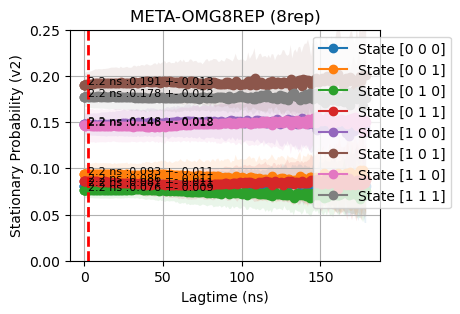

In [15]:
plt.figure(figsize=(4, 3))
state_to_plot = range(8)  # Fix: Select states 0 to 7
index = 6
select_ns = meta_omg8rep_lagtimes_ns[index]
data_rows = []

# Loop through selected states and plot each separately
for i, state in enumerate(state_to_plot):
    plt.plot(meta_omg8rep_lagtimes_ns, meta_omg8rep_pi_all_means[:, i], '-o', label=f'State {plain_md_index_to_state(state)}')
        
    # Add shaded region for standard deviation
    plt.fill_between(meta_omg8rep_lagtimes_ns, 
                     meta_omg8rep_pi_all_means[:, i] + meta_omg8rep_pi_all_stds[:, i],  # Upper bound
                     meta_omg8rep_pi_all_means[:, i] - meta_omg8rep_pi_all_stds[:, i],  # Lower bound
                     alpha=0.1)

    # Annotate the first point with its value
    first_x = meta_omg8rep_lagtimes_ns[index]
    first_y = meta_omg8rep_pi_all_means[index, i]
    first_y_var = meta_omg8rep_pi_all_stds[index, i]
    plt.text(first_x, first_y,  f"{first_x} ns :{first_y:.3f} +- {first_y_var:.3f}", fontsize=8)
    print(f"{state} {first_x}:{first_y:.3f} +- {first_y_var:.3f}")

    #Save to csv
    data_rows.append({
    'conform_state': state,
    'lagtime_index': index,
    'lagtime_ns': first_x,
    'mean': first_y,
    'std': first_y_var
        })

plt.axvline(x=first_x, color='r', linestyle='--', linewidth=2)

plt.xlabel('Lagtime (ns)')
plt.ylabel('Stationary Probability (v2)')
plt.title('META-OMG8REP (8rep)')
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1))
plt.ylim(0, 0.25)
plt.grid(True)
plt.show()


In [16]:
# === Save to CSV ===
df = pd.DataFrame(data_rows)
output_path = os.path.join(methods_path, "trans_population_at_lagtime_8conforms.csv")
df.to_csv(output_path, index=False)

print(f"✅ Saved data to: {output_path}")
df

✅ Saved data to: ../Metadynamics/analysis/autocooreldata/autocoorel_data_omg8rep/trans_population_at_lagtime_8conforms.csv


,conform_state,lagtime_index,lagtime_ns,mean,std
0,0,6,2.2,0.081357,0.010957
1,1,6,2.2,0.093396,0.010657
2,2,6,2.2,0.076178,0.008522
3,3,6,2.2,0.086172,0.011123
4,4,6,2.2,0.147792,0.011585
5,5,6,2.2,0.191021,0.013323
6,6,6,2.2,0.146395,0.017803
7,7,6,2.2,0.177689,0.011617


### oppc8rep

In [17]:
from tqdm import tqdm

methods_path = f"{metadynamics_path}/autocooreldata/autocoorel_data_oppc8rep"

meta_oppc8rep_pi_means = []
meta_oppc8rep_pi_stds =[]
for i in tqdm(range(8)):
    omega_loaded_single = Data.load(f"{methods_path}/stationary_distributions{i}.pkl").array_list

    meta_oppc8rep_pi_means_single = omega_loaded_single[0]
    meta_oppc8rep_pi_stds_single = omega_loaded_single[3]
    meta_oppc8rep_pi_means.append(meta_oppc8rep_pi_means_single)
    meta_oppc8rep_pi_stds.append(meta_oppc8rep_pi_stds_single)

meta_oppc8rep_lagtimes_ns = omega_loaded_single[8]

meta_oppc8rep_pi_means = np.array(meta_oppc8rep_pi_means)
meta_oppc8rep_pi_stds = np.array(meta_oppc8rep_pi_stds)


# Mean across all replicas
meta_oppc8rep_pi_all_means = np.nanmean(meta_oppc8rep_pi_means, axis=0)

# Law of total variance
within_var = np.nanmean(meta_oppc8rep_pi_stds**2, axis=0)  # average within-replica variance
between_var = np.nanvar(meta_oppc8rep_pi_means, axis=0, ddof=1)  # var
meta_oppc8rep_pi_all_stds = np.sqrt(within_var + between_var)

meta_oppc8rep_lagtimes_ns.shape

  0%|          | 0/8 [00:00<?, ?it/s]

100%|██████████| 8/8 [00:00<00:00, 7898.88it/s]

(184,)

2.2:0.070 +- 0.010


2.2:0.083 +- 0.012
2.2:0.075 +- 0.020
2.2:0.083 +- 0.018
2.2:0.147 +- 0.018
2.2:0.217 +- 0.041
2.2:0.143 +- 0.011
2.2:0.183 +- 0.025


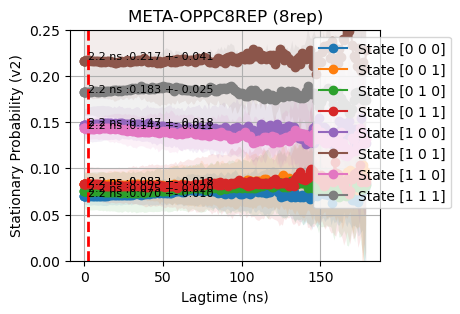

In [18]:
plt.figure(figsize=(4, 3))
state_to_plot = range(8)  # Fix: Select states 0 to 7
index = 6
select_ns = meta_oppc8rep_lagtimes_ns[index]
data_rows = []


# Loop through selected states and plot each separately
for i, state in enumerate(state_to_plot):
    plt.plot(meta_oppc8rep_lagtimes_ns, meta_oppc8rep_pi_all_means[:, i], '-o', label=f'State {plain_md_index_to_state(state)}')
        
    # Add shaded region for standard deviation
    plt.fill_between(meta_oppc8rep_lagtimes_ns, 
                     meta_oppc8rep_pi_all_means[:, i] + meta_oppc8rep_pi_all_stds[:, i],  # Upper bound
                     meta_oppc8rep_pi_all_means[:, i] - meta_oppc8rep_pi_all_stds[:, i],  # Lower bound
                     alpha=0.1)

    # Annotate the first point with its value
    first_x = meta_oppc8rep_lagtimes_ns[index]
    first_y = meta_oppc8rep_pi_all_means[index, i]
    first_y_var = meta_oppc8rep_pi_all_stds[index, i]
    plt.text(first_x, first_y,  f"{first_x} ns :{first_y:.3f} +- {first_y_var:.3f}", fontsize=8)
    print(f"{first_x}:{first_y:.3f} +- {first_y_var:.3f}")


    #Save to csv
    data_rows.append({
    'conform_state': state,
    'lagtime_index': index,
    'lagtime_ns': first_x,
    'mean': first_y,
    'std': first_y_var
        })

plt.axvline(x=first_x, color='r', linestyle='--', linewidth=2)

plt.xlabel('Lagtime (ns)')
plt.ylabel('Stationary Probability (v2)')
plt.title('META-OPPC8REP (8rep)')
plt.legend(loc='upper right', bbox_to_anchor=(1.25, 1))
plt.ylim(0, 0.25)
plt.grid(True)
plt.show()


In [19]:
# === Save to CSV ===
df = pd.DataFrame(data_rows)
output_path = os.path.join(methods_path, "trans_population_at_lagtime_8conforms.csv")
df.to_csv(output_path, index=False)

print(f"✅ Saved data to: {output_path}")
df

✅ Saved data to: ../Metadynamics/analysis/autocooreldata/autocoorel_data_oppc8rep/trans_population_at_lagtime_8conforms.csv


,conform_state,lagtime_index,lagtime_ns,mean,std
0,0,6,2.2,0.070003,0.009896
1,1,6,2.2,0.083030,0.012337
2,2,6,2.2,0.074649,0.020366
3,3,6,2.2,0.082610,0.017814
4,4,6,2.2,0.146876,0.018396
5,5,6,2.2,0.217434,0.040807
6,6,6,2.2,0.142872,0.010911
7,7,6,2.2,0.182527,0.025288


## Combine plot with log scale 

In [20]:
conformation_list = [
    'ccc','cct','ctc','ctt',
    'tcc','tct','ttc','ttt'
]

In [21]:
# Put all your methods into one list of dicts
methods_data = [
    {"name": "Plain MD", "lagtimes": plain_md_lagtimes_ns, "means": plain_md_pi_all_means, "stds": plain_md_pi_all_stds},
    {"name": "HREX", "lagtimes": hrex_lagtimes_ns, "means": hrex_pi_all_means_0, "stds": hrex_pi_all_stds_0},
    {"name": "EE", "lagtimes": ee_lagtimes_ns, "means": ee_cis_trans_pi_means[0, :, :8], "stds": ee_cis_trans_pi_stds[0, :, :8]},
    {"name": "REDS", "lagtimes": reds_lagtimes_ns, "means": reds_pi_all_means_0, "stds": reds_pi_all_stds_0},
    {"name": "META-OMG8REP", "lagtimes": meta_omg8rep_lagtimes_ns, "means": meta_omg8rep_pi_all_means, "stds": meta_omg8rep_pi_all_stds},
    {"name": "META-OPPC8REP", "lagtimes": meta_oppc8rep_lagtimes_ns, "means": meta_oppc8rep_pi_all_means, "stds": meta_oppc8rep_pi_all_stds},
]


# NOTE: the MSM (transition-matrix) stationary distribution above is not valid for a
# metadynamics-biased trajectory (it violates detailed balance / MSM assumptions).
# "META-OMG8REP" / "META-OPPC8REP" are therefore excluded from the main comparison
# (methods_data_no_meta), and are shown separately below only as a flat late-block,
# bias-reweighted reference (no lag-time dependence), not as an MSM curve.
methods_data_no_meta = [m for m in methods_data if not m["name"].startswith("META-")]

STATE_ORDER_ALPHA = [c.upper() for c in conformation_list]

def load_late_block_reference(angle):
    late = pd.read_csv(
        f"{metadynamics_path}/{angle}_state_analysis/state_analysis_results/all_replicas_late_population_average.csv"
    ).set_index("state").reindex(STATE_ORDER_ALPHA)
    return late["population"].to_numpy(), late["population_sem_across_replicas"].to_numpy()

meta_late_ref = {
    "META-OMG8REP": dict(zip(["mean", "err"], load_late_block_reference("omega"))),
    "META-OPPC8REP": dict(zip(["mean", "err"], load_late_block_reference("oppc"))),
}

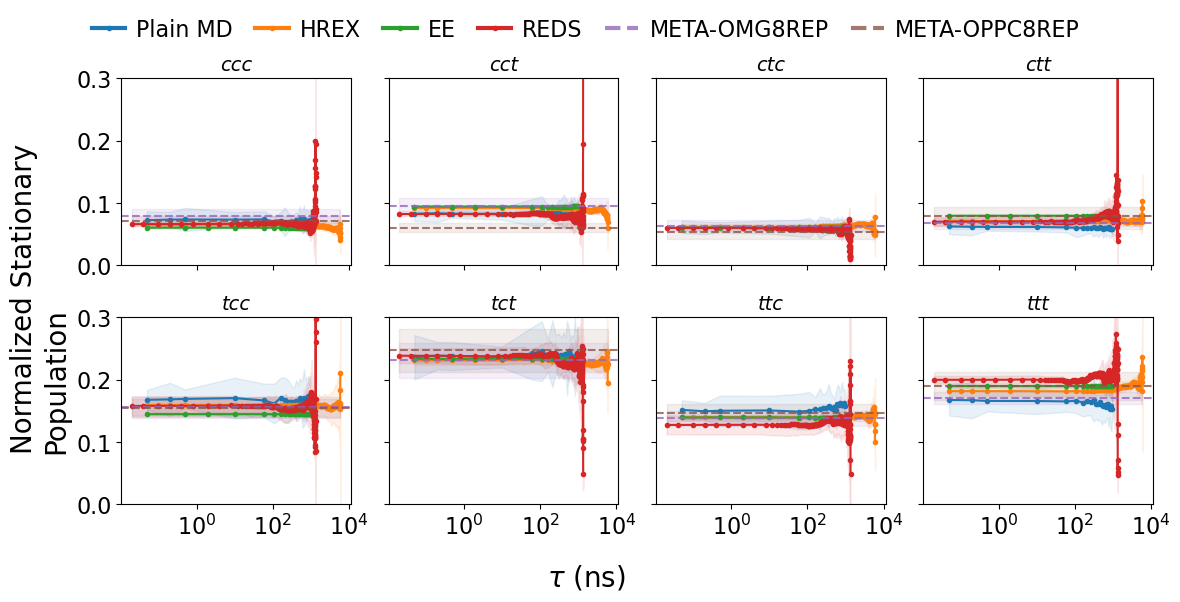

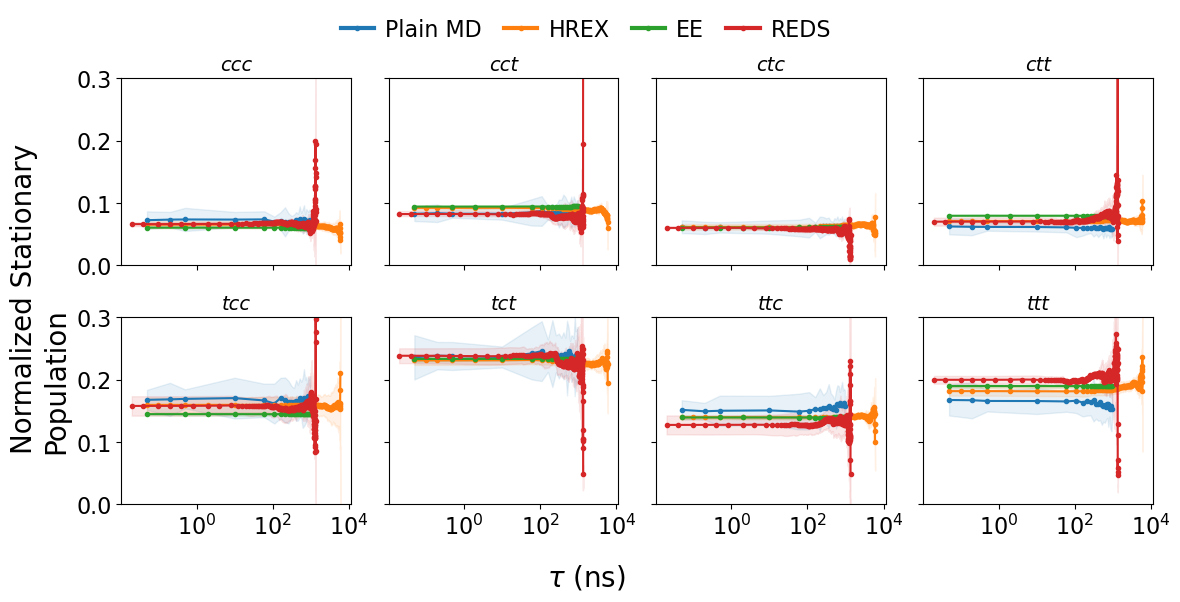

In [22]:
import matplotlib.pyplot as plt
import numpy as np

n_states = 8
titles = conformation_list
epsilon = 1e-6

from plotting_style import METHOD_COLORS, AXIS_LABEL_FONTSIZE, style_panel, add_grid_legend

method_colors = METHOD_COLORS


def plot_state_grid(methods_list, savepath, meta_refs=None):
    """methods_list: list of {"name","lagtimes","means","stds"} dicts (no Metadynamics).
    meta_refs: optional {"name": {"mean": array(8,), "err": array(8,)}} to draw as a flat
    late-block reference line per state, instead of an (invalid) MSM lagtime curve."""
    fig, axes = plt.subplots(2, 4, figsize=(12, 6), sharex=True, sharey=True)
    axes = axes.flatten()

    for state in range(n_states):
        ax = axes[state]
        for method in methods_list:
            means = np.clip(method["means"][:, state], epsilon, None)
            stds = method["stds"][:, state]
            upper = np.clip(means + stds, epsilon, None)
            lower = np.clip(means - stds, epsilon, None)

            color = method_colors[method["name"]]
            ax.plot(method["lagtimes"], means, '-o', label=method["name"], color=color, markersize=3)
            ax.fill_between(method["lagtimes"], upper, lower, color=color, alpha=0.1)

        if meta_refs:
            xlim = (min(m["lagtimes"].min() for m in methods_list), max(m["lagtimes"].max() for m in methods_list))
            for name, ref in meta_refs.items():
                color = method_colors[name]
                mean = max(ref["mean"][state], epsilon)
                err = ref["err"][state]
                ax.axhline(y=mean, linestyle='--', color=color, alpha=0.8, label=name)
                ax.fill_between(xlim, [max(mean - err, epsilon)] * 2, [mean + err] * 2, color=color, alpha=0.1)

        style_panel(ax, titles[state])
        ax.set_ylim(0, 0.3)
        ax.set_xscale("log")

    fig.supxlabel(r'$\tau$ (ns)', fontsize=AXIS_LABEL_FONTSIZE)
    fig.supylabel("Normalized Stationary\nPopulation", fontsize=AXIS_LABEL_FONTSIZE)
    add_grid_legend(fig, axes[0])

    plt.tight_layout(rect=[0, 0, 1, 0.93])
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


# Metadynamics is invalid as an MSM lag-time curve (violates detailed balance), so
# META-OMG8REP / META-OPPC8REP are shown as a flat late-block, bias-reweighted
# reference line instead -- this is the version used in the main text.
plot_state_grid(
    methods_data_no_meta, "fig/main_stationary_population_all_8_conform_log_scale.pdf",
    meta_refs=meta_late_ref,
)

# Metadynamics dropped entirely (kept for reference / comparison).
plot_state_grid(methods_data_no_meta, "fig/stationary_population_all_8_conform_log_scale_no_meta.pdf")

## Combine Plot 

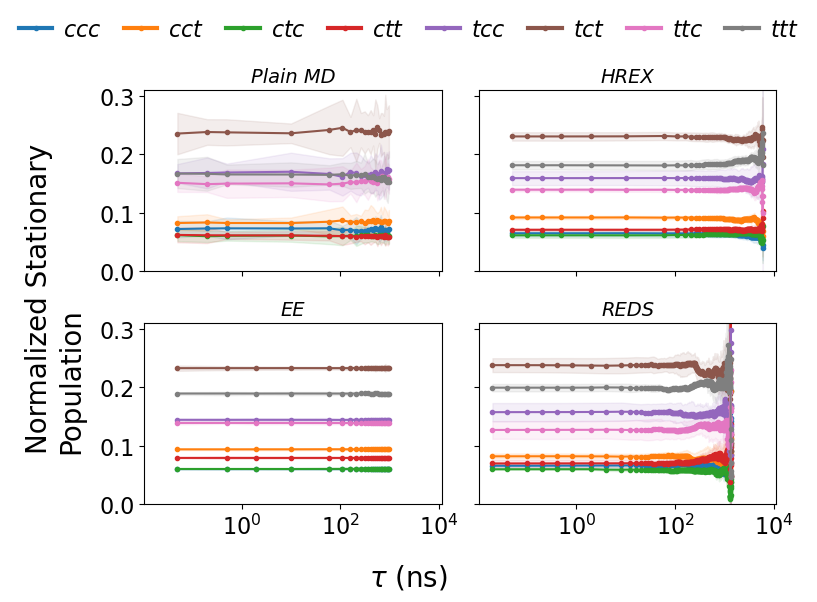

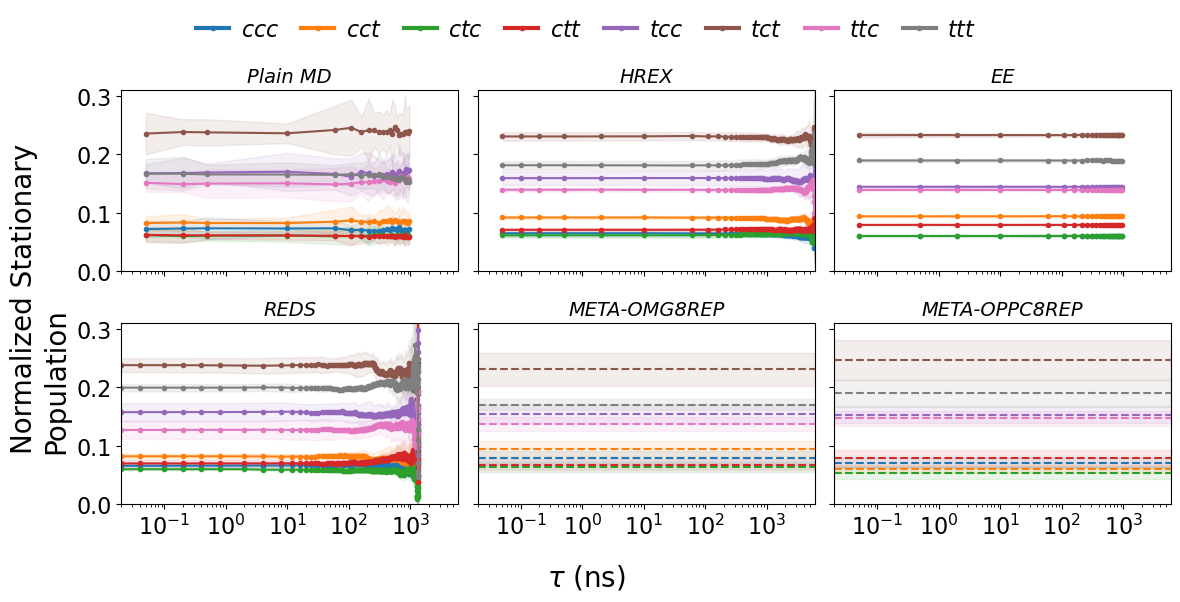

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from plotting_style import STATE_COLORS, STATE_ORDER, style_panel, TITLE_FONTSIZE

epsilon = 1e-6  # for log scale clipping
n_states = 8


def plot_method_grid(methods_list, savepath, meta_refs=None, ncols=2):
    """methods_list: list of {"name","lagtimes","means","stds"} dicts (no Metadynamics).
    meta_refs: optional {"name": {"mean": array(8,), "err": array(8,)}} -> each gets its
    own panel, drawn as 8 flat late-block reference lines (one per state) instead of an
    (invalid) MSM lag-time curve.

    Each panel = one method; the 8 conformer states are overlaid as separate
    curves within it, colored by STATE_COLORS (plotting_style.py) so every
    panel of every such figure colors e.g. `ttt` identically, and labeled by
    its real three-letter conformer name (not a generic index)."""
    panels = list(methods_list) + ([{"name": n, "ref": r} for n, r in meta_refs.items()] if meta_refs else [])
    nrows = -(-len(panels) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), sharex=True, sharey=True)
    axes = np.atleast_1d(axes).flatten()

    xlim = (min(m["lagtimes"].min() for m in methods_list), max(m["lagtimes"].max() for m in methods_list))

    for idx, panel in enumerate(panels):
        ax = axes[idx]
        if "ref" in panel:
            for state, state_label in enumerate(STATE_ORDER):
                color = STATE_COLORS[state_label]
                mean = max(panel["ref"]["mean"][state], epsilon)
                err = panel["ref"]["err"][state]
                ax.axhline(y=mean, linestyle='--', color=color, label=fr"$\mathit{{{state_label}}}$")
                ax.fill_between(xlim, [max(mean - err, epsilon)] * 2, [mean + err] * 2,
                                 color=color, alpha=0.1)
            ax.set_xlim(*xlim)
        else:
            lagtimes = panel["lagtimes"]
            for state, state_label in enumerate(STATE_ORDER):
                color = STATE_COLORS[state_label]
                means = np.clip(panel["means"][:, state], epsilon, None)
                stds = panel["stds"][:, state]
                upper = np.clip(means + stds, epsilon, None)
                lower = np.clip(means - stds, epsilon, None)
                ax.plot(lagtimes, means, '-o', label=fr"$\mathit{{{state_label}}}$", color=color, markersize=3)
                ax.fill_between(lagtimes, upper, lower, color=color, alpha=0.1)

        style_panel(ax, panel["name"], tick_fontsize=16, title_fontsize=TITLE_FONTSIZE)
        ax.set_xscale("log")
        ax.set_ylim(0, 0.31)

    for idx in range(len(panels), len(axes)):
        axes[idx].axis("off")

    fig.supxlabel(r'$\tau$ (ns)', fontsize=20)
    fig.supylabel("Normalized Stationary\nPopulation", fontsize=20)

    handles, labels = axes[0].get_legend_handles_labels()
    leg = fig.legend(
        handles, labels,
        loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=8,
        frameon=False, handlelength=1.5, handletextpad=0.5, columnspacing=1.0, fontsize=16
    )
    for line in leg.get_lines():
        line.set_linewidth(3.0)

    plt.tight_layout(rect=[0, 0, 1, 0.91])
    plt.savefig(savepath, dpi=300, bbox_inches='tight')
    plt.show()


# Version 1: Metadynamics dropped entirely.
plot_method_grid(methods_data_no_meta, "fig/stationary_population_all_8_conform.pdf")

# Version 2: Metadynamics panels shown as flat late-block, bias-reweighted reference
# lines (per state), instead of an MSM lag-time curve.
plot_method_grid(
    methods_data_no_meta, "fig/stationary_population_all_8_conform_with_late_block_ref.pdf",
    meta_refs=meta_late_ref, ncols=3,
)

## SI: full PBMetaD CV-combination comparison (all methods, no late-block substitution)

For the SI (not the main text), show the same "MSM-derived stationary probability
vs. lag time, per-method panel, 8 conformer states overlaid" view as the
`fig/stationary_population_all_8_conform.pdf` figure above, but for *every*
PBMetaD CV combination tested (`ANALYSIS_RULES.md` §5), not just the two 8-walker
variants used in the main text: the single-replica omega+phi (META-OPH) and
omega+phi+psi (META-OPP) runs (intended for the SI only), plus the single-replica
omega+phi+psi+chi (META-OPPC) run, alongside META-OMG8REP/META-OPPC8REP. This
reuses each variant's own already-computed `stationary_distributions.pkl` (same
MSM-v2 pipeline already applied to omg8rep/oppc8rep above) -- no new methodology.
This view is for completeness/transparency in the SI only; the main text still
treats all PBMetaD variants as scientifically invalid for an MSM lag-time curve
(Section 3.2 of `ANALYSIS_RULES.md`) and shows them instead as a flat,
bias-reweighted late-block reference (see `..._with_late_block_ref.pdf` above).
This overwrites `fig/stationary_population_all_8_conform.pdf` (previously the
4-panel Plain MD/HREX/EE/REDS-only version) with the fuller 9-panel version the
SI document expects.

In [24]:
updated_tm_path = f"{metadynamics_path}/updated_transitionmatrix"

single_replica_meta = {}
for cv_name, folder in [("META-OPH", "autocoorel_data_oph"), ("META-OPP", "autocoorel_data_opp"),
                         ("META-OPPC", "autocoorel_data_oppc")]:
    loaded = Data.load(f"{updated_tm_path}/{folder}/stationary_distributions.pkl").array_list
    single_replica_meta[cv_name] = {
        "name": cv_name,
        "lagtimes": np.array(loaded[8]),
        "means": np.array(loaded[0]),
        "stds": np.array(loaded[3]),
    }
    print(cv_name, single_replica_meta[cv_name]["means"].shape, single_replica_meta[cv_name]["lagtimes"].shape)


META-OPH (184, 8) (184,)
META-OPP (184, 8) (184,)
META-OPPC (184, 8) (184,)


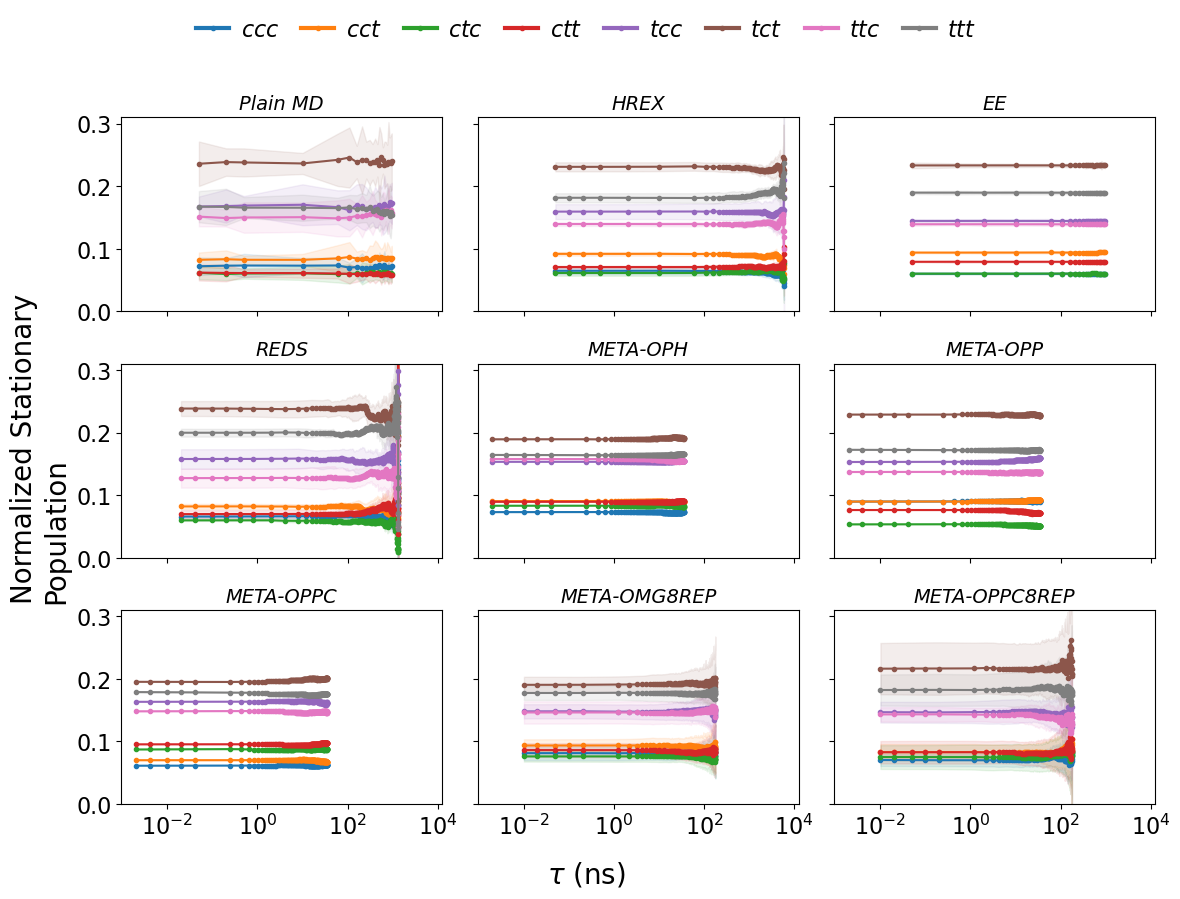

In [25]:
meta_8rep_curves = [m for m in methods_data if m["name"] in ("META-OMG8REP", "META-OPPC8REP")]

methods_data_si_full = (
    methods_data_no_meta
    + [single_replica_meta["META-OPH"], single_replica_meta["META-OPP"], single_replica_meta["META-OPPC"]]
    + meta_8rep_curves
)

plot_method_grid(methods_data_si_full, "fig/SI_stationary_8conform_lagtime_allCVs.pdf", ncols=3)


## SI: Metadynamics-only CV-combination comparison

A standalone version of the figure above containing only the panels that
have no Plain MD/EE/HREX/REDS counterpart -- i.e. only the PBMetaD
collective-variable combinations (single-replica META-OPH, META-OPP,
META-OPPC, plus the 8-walker META-OMG8REP/META-OPPC8REP). Same
`plot_method_grid` view, same STATE_COLORS-by-conformer-state coloring, just
restricted to the Metadynamics-only panels for a figure focused purely on
comparing PBMetaD CV choices against each other.

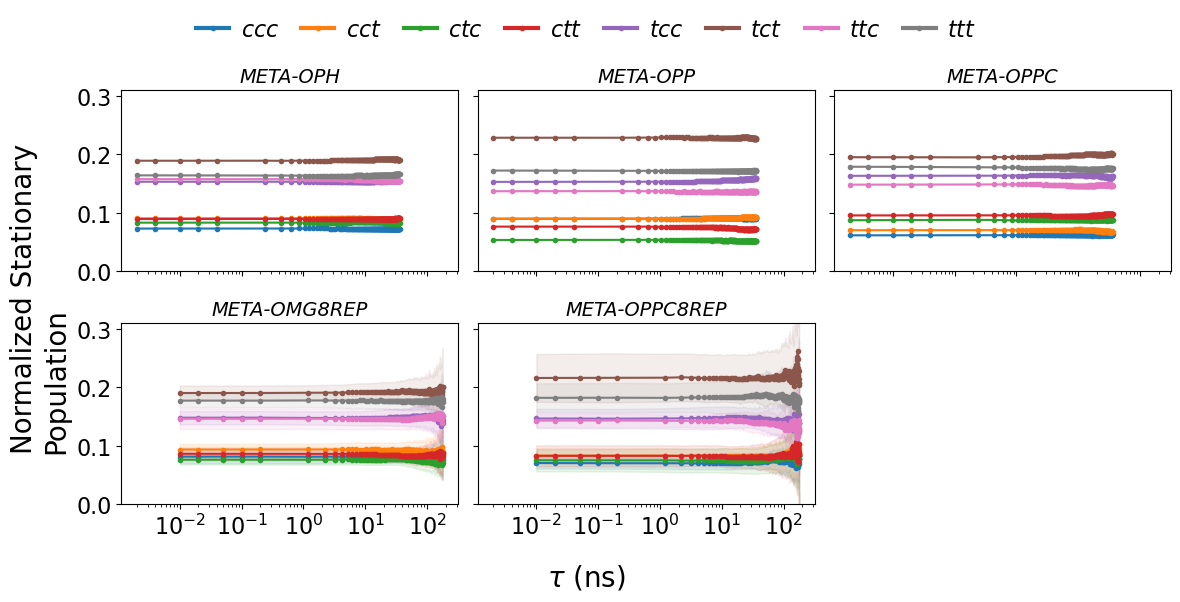

In [26]:
methods_data_meta_only = (
    [single_replica_meta["META-OPH"], single_replica_meta["META-OPP"], single_replica_meta["META-OPPC"]]
    + meta_8rep_curves
)

plot_method_grid(methods_data_meta_only, "fig/SI_stationary_8conform_metadynamics_only.pdf", ncols=3)